> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# IS 4487 Lab 12: Naive Bayes, SVM, and Neural Networks

## Outline

- Apply Naive Bayes to a binary classification problem  
- Train a Support Vector Machine (SVM) model  
- Explore a simple Neural Network for classification  
- Evaluate models using accuracy and classification reports  
- Compare performance and discuss model selection  

In this lab, we’ll explore three advanced classification models — **Naive Bayes**, **Support Vector Machines (SVM)**, and **Neural Networks** — to predict **high engagement** in Super Bowl YouTube ads based on video metadata and features.

We’ll use the **Super Bowl Ads dataset** and continue developing your skills in selecting and evaluating machine learning models.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Labs/lab_12_bayes_svm_neural.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Superbowl Ads: Business Context

The dataset for this lab consists of YouTube metadata and thematic features of Super Bowl commercials.  

This dataset captures Super Bowl advertisements and their performance on YouTube, providing a valuable business context around marketing effectiveness and audience engagement. Super Bowl ads are some of the most expensive and high-profile advertisements in the world, so companies are highly interested in understanding what makes an ad successful. The variables in this dataset describe both the content of the ads (such as whether they are funny, include celebrities, use animals, or feature patriotic themes) and their performance outcomes (like views, likes, comments, and overall engagement). Businesses can use this data to analyze which creative elements are associated with higher audience engagement—for example, whether humorous ads or celebrity appearances lead to more likes or shares. By using the high_engagement variable as a target, analysts can even build predictive models to determine what combination of features is most likely to result in a successful ad. Insights from this type of analysis can help marketing teams design more effective campaigns, allocate advertising budgets more strategically, and maximize the return on their investment in major events like the Super Bowl.

Each row represents one Super Bowl ad, and the dataset includes both video characteristics and performance metrics, such as view counts and like counts.


## Data Dictionary
Source: [TidyTuesday (March 2, 2021)](https://github.com/rfordatascience/tidytuesday/blob/master/data/2021/2021-03-02/youtube.csv).

| Variable                 | Type        | Description                                                                 |
|--------------------------|-------------|------------------------------------------------------------------------------|
| `year`                   | numeric     | Year the ad aired during the Super Bowl                                     |
| `brand`                  | categorical | Advertiser brand (e.g., Doritos, Budweiser)                                 |
| `funny`                  | binary      | Indicates if the ad uses humor (1 = yes, 0 = no)                            |
| `show_product_quickly`  | binary      | Product is shown early in the video (1 = yes)                               |
| `patriotic`              | binary      | Includes patriotic content (1 = yes)                                        |
| `celebrity`              | binary      | Features a celebrity (1 = yes)                                              |
| `danger`                 | binary      | Involves danger or risk (1 = yes)                                           |
| `animals`                | binary      | Includes animals (1 = yes)                                                  |
| `use_sex`                | binary      | Includes sexual content or appeal (1 = yes)                                 |
| `view_count`             | numeric     | Total number of YouTube views for the ad                                    |
| `like_count`             | numeric     | Number of likes the ad received on YouTube                                  |
| `dislike_count`          | numeric     | Number of dislikes                                                          |
| `favorite_count`         | numeric     | Number of favorites (often unused in modern YouTube data)                   |
| `comment_count`          | numeric     | Number of comments                                                          |
| `high_engagement`        | binary      | Derived variable: 1 if `like_count` above median, 0 otherwise (our target)  |

### Why this dataset?

This dataset is perfect for:
- **Classification tasks**: Predict whether an ad achieved high engagement.
- **Marketing insights**: Identify which ad traits (e.g., humor, celebrities) drive viewer responses.
- **Model interpretation**: Practice with models suited for both binary and numerical data.

Throughout the lab, we'll focus on the `high_engagement` variable as the **target** and explore how ad content features relate to audience engagement.


## Part 1: Load and Clean the Data

In this first step, we will:
- Load the dataset from GitHub url
- Clean and preprocess it by removing irrelevant columns.
- Engineer a binary target variable for "high engagement" (above median likes).

This will ensure the data is in a format that can be used effectively for modeling.


In [14]:
import pandas as pd
import numpy as np

# Load dataset
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/youtube.csv'
youtube = pd.read_csv(url)

# Drop irrelevant or complex API columns
youtube = youtube.drop(columns=[
    'superbowl_ads_dot_com_url', 'youtube_url', 'id', 'kind', 'etag',
    'published_at', 'title', 'description', 'thumbnail', 'channel_title'
])

# Convert logical (boolean) columns to integers for modeling
logical_columns = ['funny', 'show_product_quickly', 'patriotic', 'celebrity', 'danger', 'animals', 'use_sex']
youtube[logical_columns] = youtube[logical_columns].astype(int)

# Drop rows with missing like_count
youtube = youtube.dropna(subset=['like_count', 'view_count'])

# Create target: high_engagement
median_likes = youtube['like_count'].median()
youtube['high_engagement'] = (youtube['like_count'] > median_likes).astype(int)


# Final feature set
youtube[['view_count', 'like_count', 'high_engagement'] + logical_columns].head()

,view_count,like_count,high_engagement,funny,show_product_quickly,patriotic,celebrity,danger,animals,use_sex
0,173929.0,1233.0,1,0,0,0,0,0,0,0
1,47752.0,485.0,1,1,1,0,1,1,0,0
2,142310.0,129.0,0,1,0,0,0,1,1,0
3,198.0,2.0,0,0,1,0,0,0,0,0
4,13741.0,20.0,0,1,1,0,0,1,1,1


## Part 2: Naive Bayes Classifier

Naive Bayes is a **probabilistic model** based on Bayes' Theorem. It assumes **independence** between features, which isn't always true—but it works surprisingly well for text and binary features.

We'll use the boolean ad features (like `funny`, `celebrity`, etc.) to predict whether the video had high engagement.

Ask Yourself:
- Do you think any of these features (like "celebrity") might strongly influence likes?
- How might the independence assumption affect the predictions?

Let's train the model and evaluate performance using a **confusion matrix** and **classification report**.


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Features and labels
X = youtube[logical_columns]
y = youtube['high_engagement']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Fit model
nb_model = BernoulliNB()
nb_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_nb = nb_model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))
print("Accuracy:", accuracy_score(y_test, y_pred_nb))

Confusion Matrix:
 [[19 19]
 [16 14]]

Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.50      0.52        38
           1       0.42      0.47      0.44        30

    accuracy                           0.49        68
   macro avg       0.48      0.48      0.48        68
weighted avg       0.49      0.49      0.49        68

Accuracy: 0.4852941176470588


### 🔧 Do the following — Part 2

1. **Change the test size** to `0.2`. How does this affect accuracy?  
   > Update `train_test_split(test_size=0.2)` and rerun the model.

2. **Remove `celebrity` and `funny` features** from X. Rerun the model and check performance.  
   > Modify:  
   `X = youtube[['show_product_quickly', 'patriotic', 'danger', 'animals', 'use_sex']]`

In [16]:
y = youtube['high_engagement']

X = youtube[logical_columns]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_pred = BernoulliNB().fit(X_train, y_train).predict(X_test)
print("TASK 1 (test_size=0.2)")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred), "\n")

X = youtube[['show_product_quickly', 'patriotic', 'danger', 'animals', 'use_sex']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_pred = BernoulliNB().fit(X_train, y_train).predict(X_test)
print("TASK 2 (no celebrity/funny)")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

TASK 1 (test_size=0.2)
[[15 12]
 [ 8 10]]
              precision    recall  f1-score   support

           0       0.65      0.56      0.60        27
           1       0.45      0.56      0.50        18

    accuracy                           0.56        45
   macro avg       0.55      0.56      0.55        45
weighted avg       0.57      0.56      0.56        45

Accuracy: 0.5555555555555556 

TASK 2 (no celebrity/funny)
[[13 14]
 [ 9  9]]
              precision    recall  f1-score   support

           0       0.59      0.48      0.53        27
           1       0.39      0.50      0.44        18

    accuracy                           0.49        45
   macro avg       0.49      0.49      0.48        45
weighted avg       0.51      0.49      0.49        45

Accuracy: 0.4888888888888889


### Reflection:

1. Which model setup performed best? Why might that be?

### ✍️ Your Response: 🔧
1. Task 1 performed the best with a test size of 0.2. Accuracy was 0.556 compared to 0.489 on Task 2. The fact that Task 1 had more features could've helped. Celebrity and funny could have been a useful signal for engagement, and removing them left the second model with less to work with, dropping accuracy.

## Part 3: Support Vector Machine (SVM)

### What you're going to do:
Use a **Support Vector Machine** to classify ads, using both binary and numeric features.

The SVM section begins by selecting the input features and target, then splitting the data into training and test sets to ensure fair evaluation. The features are scaled using a StandardScaler fit only on the training data so that all variables are on a comparable scale, which is important for SVM performance.

A support vector machine model is then trained on the scaled training data, optionally using cross-validation to tune hyperparameters like the kernel and regularization strength.

Finally, the trained model is used to make predictions on the untouched test set, and its performance is evaluated using metrics such as accuracy and a confusion matrix.

### Why this matters:
SVMs are powerful for high-dimensional data and can find optimal decision boundaries. They are also common in fraud detection and image recognition.

### Regularization Parameter (C):

- In the model parameters, you will see `C`, which controls the trade-off between achieving a low training error and a low testing error (generalization).

- A large `C` value (e.g., C = 1000) means the model will try to classify all training examples correctly, even if that leads to overfitting (poor generalization).

- A small `C` value (e.g., C = 0.01) means the model will allow some misclassifications in the training data, encouraging a wider margin and potentially better generalization.

### What to notice:
- How does scaling the data affect performance?
- What happens when you change the kernel or regularization?

In [17]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

X = youtube[logical_columns + ['view_count']]
y = youtube['high_engagement']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svm_model = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("Accuracy:", accuracy_score(y_test, y_pred_svm))


Confusion Matrix:
 [[25  9]
 [13 21]]

Classification Report:
               precision    recall  f1-score   support

           0       0.66      0.74      0.69        34
           1       0.70      0.62      0.66        34

    accuracy                           0.68        68
   macro avg       0.68      0.68      0.68        68
weighted avg       0.68      0.68      0.68        68

Accuracy: 0.6764705882352942


### 🔧 Do the following — Part 3

1. **Change the kernel** to `'linear'` or `'poly'`.  
2. **Try 2 different `C` values** like `0.1`, `1`, and `10`. Observe what changes.

In [18]:
# 🔧 Add code here:
X = youtube[logical_columns + ['view_count']]
y = youtube['high_engagement']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

for kernel in ['rbf', 'linear', 'poly']:
    for C in [0.1, 1, 10]:
        svm_model = SVC(kernel=kernel, C=C, gamma='scale')
        svm_model.fit(X_train_scaled, y_train)
        y_pred_svm = svm_model.predict(X_test_scaled)
        print(f"kernel={kernel:6} C={C:<4} Accuracy: {accuracy_score(y_test, y_pred_svm):.3f}")

kernel=rbf    C=0.1  Accuracy: 0.500
kernel=rbf    C=1    Accuracy: 0.676
kernel=rbf    C=10   Accuracy: 0.618
kernel=linear C=0.1  Accuracy: 0.515
kernel=linear C=1    Accuracy: 0.515
kernel=linear C=10   Accuracy: 0.691
kernel=poly   C=0.1  Accuracy: 0.500
kernel=poly   C=1    Accuracy: 0.676
kernel=poly   C=10   Accuracy: 0.632


### Reflection:
1. What’s the tradeoff between higher and lower values of `C`?
2. Which value of C gave you the best Accuracy?  

### ✍️ Your Response: 🔧
1. C controls how stricly the SVM model tries to classify every training example correctly. Lower C's and the model tolerates misclassified data points and keeps a wider margin, this tends to allow for better generalization. Higher C's and the model tries hard to fit every data point, agiving narrower margin and a more complex boundary. They capture more detail but is more prone to overfitting.
2. C=10 with kernal linearity gave me the best accuracy, which was 0.691.

## Part 4: Neural Networks

### What you're going to do:
The neural network script takes raw data and turns it into a trained and evaluated model.

First, it defines the input features (X) and the target variable (y). Then, it splits the dataset into three parts: a training set used to learn the model, a validation set used to monitor performance during training, and a test set reserved for final evaluation. After splitting, the features are scaled using a StandardScaler, which is fit only on the training data and then applied to the validation and test sets to keep everything consistent without introducing leakage.

Next, the neural network is built using a series of dense layers, ending with a sigmoid output for binary classification. The model is then compiled, specifying how it will learn (optimizer), how errors are measured (loss function), and what metrics to track. During training, the model learns from the training data while periodically evaluating itself on the validation set to track progress and detect overfitting. Once training is complete, the model makes predictions on the untouched test set, and its performance is evaluated using metrics like accuracy, a confusion matrix, and a classification report. This entire flow ensures that the model is trained properly and evaluated fairly on data it has never seen before.

We will use the `Scaler` to transform big numbers, like `view_count` into a small range, with the average value as 0 and each standard deviation is 1.  

### Why this matters:
Neural networks are the foundation of modern AI. Even a simple one can outperform traditional models when tuned correctly.

### What to notice:
- This may take several minutes to run!  Be patient.
- How does training accuracy compare to validation accuracy?
- Do more layers or epochs help — or hurt?


In [19]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Build features and target from the raw dataframe again
X_nn = youtube[logical_columns + ['view_count']]
y_nn = youtube['high_engagement']

# Hold out the final test set first
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_nn, y_nn, test_size=0.30, random_state=42, stratify=y_nn
)

# Split training data into train + true validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=42, stratify=y_train_full
)

# Fit a fresh scaler on NN training data only
nn_scaler = StandardScaler()
X_train = nn_scaler.fit_transform(X_train)
X_val = nn_scaler.transform(X_val)
X_test = nn_scaler.transform(X_test)

# Build the neural net with 4 layers
model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(8, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train with the neural net with the real validation split
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=16,
    verbose=1
)

#  Do a final evaluation only on untouched test data
y_pred_nn = (model.predict(X_test) > 0.5).astype(int).ravel()

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nn))
print("Accuracy:", accuracy_score(y_test, y_pred_nn))


Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.4960 - loss: 0.7138 - val_accuracy: 0.4688 - val_loss: 0.6963
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5200 - loss: 0.7091 - val_accuracy: 0.4688 - val_loss: 0.6955
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5440 - loss: 0.7056 - val_accuracy: 0.5312 - val_loss: 0.6950
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5440 - loss: 0.7027 - val_accuracy: 0.5312 - val_loss: 0.6948
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5440 - loss: 0.7001 - val_accuracy: 0.5000 - val_loss: 0.6943
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5520 - loss: 0.6976 - val_accuracy: 0.5000 - val_loss: 0.6937
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5680 - loss: 0.6953 - val_accuracy: 0.5312 - val_loss: 0.6931
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5920 - loss: 0.6931 - val_accuracy: 0.5312 - val_loss: 0.6927
Epoch 9/20


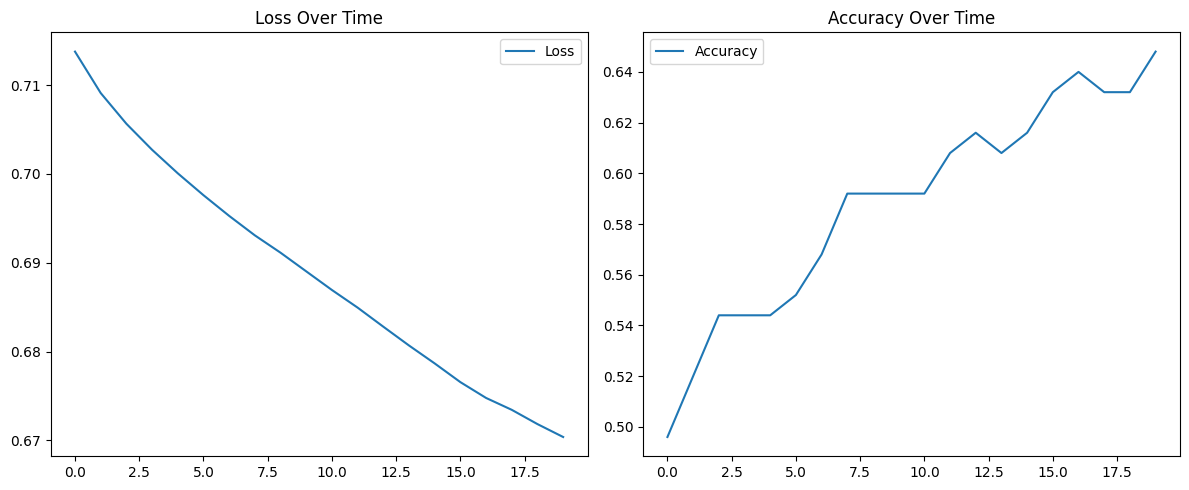

In [20]:
# Plot learning curves
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss')
plt.title('Loss Over Time')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy')
plt.title('Accuracy Over Time')
plt.legend()
plt.tight_layout()
plt.show()

### 🔧 Do the following — Part 4

1. Add or remove layers from the model.
2. Increase or decrease batch size to numbers such as 8 or 32. Try out 5 different combinations of different batch sizes and layers. Notice if these changes affect ms/step for each Epoch. Also notice how the accuracy changes as you alter layers and batch size.
3. Add Dropout to your model

--- Model 1: 2 layers, batch_size=8 ---
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.4720 - loss: 0.7623 - val_accuracy: 0.5000 - val_loss: 0.7151
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4640 - loss: 0.7483 - val_accuracy: 0.5000 - val_loss: 0.7093
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4640 - loss: 0.7380 - val_accuracy: 0.5000 - val_loss: 0.7050
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4560 - loss: 0.7295 - val_accuracy: 0.4688 - val_loss: 0.7019
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4640 - loss: 0.7222 - val_accuracy: 0.4688 - val_loss: 0.6995
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4640 - loss: 0.7160 - val_accuracy: 0.5312 - val_loss: 0.6978
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5120 - loss: 0.7106 - val_accuracy: 0.5312 - val_loss: 0.6965
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5120 - loss: 0.7058 - val_accuracy: 0.5312 - val_loss: 0.6956
Ep

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.4960 - loss: 0.7238 - val_accuracy: 0.5000 - val_loss: 0.6904
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4960 - loss: 0.7184 - val_accuracy: 0.5000 - val_loss: 0.6883
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4960 - loss: 0.7139 - val_accuracy: 0.5000 - val_loss: 0.6863
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4800 - loss: 0.7099 - val_accuracy: 0.5312 - val_loss: 0.6847
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4880 - loss: 0.7063 - val_accuracy: 0.5312 - val_loss: 0.6833
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4960 - loss: 0.7031 - val_accuracy: 0.5625 - val_loss: 0.6821
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5040 - loss: 0.7005 - val_accuracy: 0.5625 - val_loss: 0.6812
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5040 - loss: 0.6982 - val_accuracy: 0.5625 - val_loss: 0.6806
Epoch 9/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.5040 - loss: 0.7068 - val_accuracy: 0.5000 - val_loss: 0.6958
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5040 - loss: 0.7007 - val_accuracy: 0.5000 - val_loss: 0.6950
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5040 - loss: 0.6968 - val_accuracy: 0.5000 - val_loss: 0.6940
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5040 - loss: 0.6935 - val_accuracy: 0.5000 - val_loss: 0.6934
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5040 - loss: 0.6906 - val_accuracy: 0.5000 - val_loss: 0.6928
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5040 - loss: 0.6884 - val_accuracy: 0.5000 - val_loss: 0.6924
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5120 - loss: 0.6864 - val_accuracy: 0.5000 - val_loss: 0.6926
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5120 - loss: 0.6845 - val_accuracy: 0.5000 - val_loss: 0.6930
Epoch 9/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.4800 - loss: 0.7402 - val_accuracy: 0.4688 - val_loss: 0.7265
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4640 - loss: 0.7280 - val_accuracy: 0.4688 - val_loss: 0.7241
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5520 - loss: 0.7293 - val_accuracy: 0.5000 - val_loss: 0.7226
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4720 - loss: 0.7409 - val_accuracy: 0.5000 - val_loss: 0.7217
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5280 - loss: 0.7223 - val_accuracy: 0.5000 - val_loss: 0.7212
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4960 - loss: 0.7272 - val_accuracy: 0.4688 - val_loss: 0.7217
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5200 - loss: 0.7405 - val_accuracy: 0.4375 - val_loss: 0.7222
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5280 - loss: 0.7004 - val_accuracy: 0.4375 - val_loss: 0.7225
Epoch 9/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4480 - loss: 0.8445 - val_accuracy: 0.5000 - val_loss: 0.6909
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5280 - loss: 0.7358 - val_accuracy: 0.5000 - val_loss: 0.6867
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4640 - loss: 0.7318 - val_accuracy: 0.4688 - val_loss: 0.6837
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5680 - loss: 0.7391 - val_accuracy: 0.5312 - val_loss: 0.6818
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5040 - loss: 0.7216 - val_accuracy: 0.5312 - val_loss: 0.6817
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5120 - loss: 0.7250 - val_accuracy: 0.5312 - val_loss: 0.6815
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4960 - loss: 0.7117 - val_accuracy: 0.5312 - val_loss: 0.6824
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4880 - loss: 0.7433 - val_accuracy: 0.5312 - val_loss: 0.6821
Ep

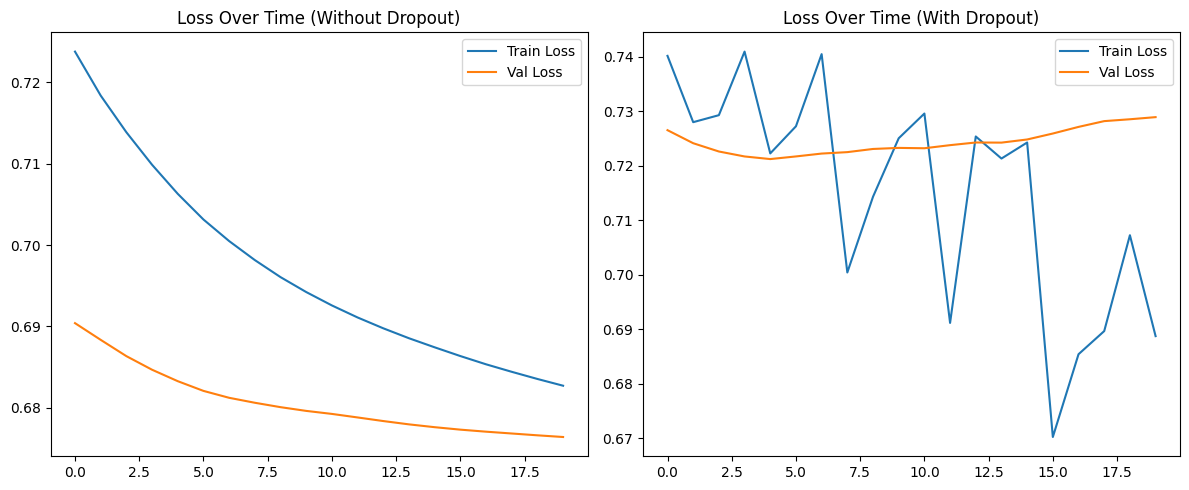

In [21]:
# Combination 1: Fewer layers (2 layers), smaller batch size (8)
tf.random.set_seed(42)
model_1 = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(1, activation='sigmoid')
])
model_1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("--- Model 1: 2 layers, batch_size=8 ---")
history_1 = model_1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=8, verbose=1)
acc_1 = accuracy_score(y_test, (model_1.predict(X_test) > 0.5).astype(int).ravel())


# Combination 2: Original 4 layers, larger batch size (32)
tf.random.set_seed(42)
model_2 = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(8, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("\n--- Model 2: 4 layers, batch_size=32 ---")
history_2 = model_2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32, verbose=1)
acc_2 = accuracy_score(y_test, (model_2.predict(X_test) > 0.5).astype(int).ravel())


# Combination 3: More layers (5 layers), batch size (16)
tf.random.set_seed(42)
model_3 = Sequential([
    Dense(32, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("\n--- Model 3: 5 layers, batch_size=16 ---")
history_3 = model_3.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=16, verbose=1)
acc_3 = accuracy_score(y_test, (model_3.predict(X_test) > 0.5).astype(int).ravel())


# Combination 4: 3 layers with Dropout (0.3), batch size (16)
tf.random.set_seed(42)
model_4 = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(8, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
model_4.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("\n--- Model 4: 3 layers + Dropout, batch_size=16 ---")
history_4 = model_4.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=16, verbose=1)
acc_4 = accuracy_score(y_test, (model_4.predict(X_test) > 0.5).astype(int).ravel())


# Combination 5: 3 layers with Dropout (0.3), smaller batch size (8)
tf.random.set_seed(42)
model_5 = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(8, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
model_5.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print("\n--- Model 5: 3 layers + Dropout, batch_size=8 ---")
history_5 = model_5.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=8, verbose=1)
acc_5 = accuracy_score(y_test, (model_5.predict(X_test) > 0.5).astype(int).ravel())


# Summary of Test Accuracies
print("\n=== Test Accuracy Summary ===")
print(f"Model 1 (2 layers, batch 8):            {acc_1:.3f}")
print(f"Model 2 (4 layers, batch 32):           {acc_2:.3f}")
print(f"Model 3 (5 layers, batch 16):           {acc_3:.3f}")
print(f"Model 4 (3 layers + Dropout, batch 16): {acc_4:.3f}")
print(f"Model 5 (3 layers + Dropout, batch 8):  {acc_5:.3f}")

# Plot Loss Over Time to compare Without Dropout vs. With Dropout
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_2.history['loss'], label='Train Loss')
plt.plot(history_2.history['val_loss'], label='Val Loss')
plt.title('Loss Over Time (Without Dropout)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_4.history['loss'], label='Train Loss')
plt.plot(history_4.history['val_loss'], label='Val Loss')
plt.title('Loss Over Time (With Dropout)')
plt.legend()

plt.tight_layout()
plt.show()

### Reflection:
1. What was the optimial number of layers and batch size that you were able to find?  (Remember, you should try about 5 different combinations)
2. Does adding `Dropout` help reduce overfitting? Use the "loss over time" plot to support your answer.

### ✍️ Your Response: 🔧
1. The optimal number of layers and batch size was 3 layers with a batch size of 8. That combination gave me an accuracy of 0.603 compared to the other 4 combinations which reached 0.574 at best.
2. Yes, in the loss over time without dropout plot, training loss drops sharply down to .68 while validation loss remains higher, around 0.695, creating a wide gap that indicates overfitting. In the with dropout plot, training loss is higher, while validation loss downtrends and converges with training loss. This shows improved generalization and less overfitting.

## 🔧 Part 5: Reflection (100 words or less per question)

1. Which model performed best on your dataset? Is this the result you expected?
2. Did any of the models appear to be overfit or underfit? How could you tell?
3. Which model would you recommend to a marketing team and why?

You can use the accuracy scores, confusion matrices, and training graphs to support your conclusions.


### ✍️ Your Response: 🔧
1. The linear SVM (C=10) perfomred the best with .691 accuracy, which outperformed Naive Bayes (0.556 accuracy) and Neural Network (0.603). Yes, this aligns with my expectations, considering the dataset was small and consisted mostly of binary rows, a classifier like SVM generalizes well without memorizing noise. Neural Network models would be better if the dataset was bigger, more complex, and nonlinear.
2. Yes, the baseline and 5 layer neural network showed overfitting. In the 5 layer model, training accuracy was 0.664 while validation dropped to 0.469, and validation loss increased. SVM models with low C values showed underfitting  because they seemed to be too simple or over-regularized to capture any useful patterns.
3. I would recommend the linear SVM (C=10). It achieved the highest test accuracy and balanced performance on unseen ads  without the instability seen in neural network models. The linear SVM models are also faster to train, generalize reliably on small datasets, and can be a dependable tool for small marketing teams in need of model to help predict ad engagement.

## Export Your Notebook to Submit in Canvas
- Use the instructions from Lab 1

In [22]:
!jupyter nbconvert --to html "lab_12_bayes_svm_neural.ipynb"

[NbConvertApp] WARNING | pattern 'lab_12_bayes_svm_neural.ipynb' matched no files
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
-